# Exploratory Data Analysis (EDA)

All exploratory analysis, statistical diagnostics, and modeling choices are conducted **exclusively on the Training Set (2024)**. The Validation (Q1 2025) and Test (Q2 2025) partitions remain strictly untouched and reserved for model selection and out-of-sample evaluation.

The analysis is structured around **four critical decision**:
1. **Temporal Patterns**: Identify 24h and 168h cycles to justify daily/weekly persistence and seasonal terms (SARIMA).
2. **Price Distribution**: Quantify scale, extreme spikes, and non-positive prices to select evaluation metrics (MAE, RMSE) and justify non-linear models (XGBoost).
3. **Spatial Coupling**: Measure cross-node correlation and absolute price discrepancies to justify developing initial models on the node (`06MON-115`).
4. **Information Timeline & Decisions**: Formalize Day-Ahead Market (MDA) information boundaries (prohibiting look-ahead bias) and define the candidate model benchmark roadmap.

## Data Ingestion & Chronological Partitioning
We partition the 547-day dataset into contiguous chronological splits before conducting any statistical analysis. (train, validation and test)

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
parquet_path = ROOT_DIR / "data/interim/pml_mda.parquet"

df = pd.read_parquet(parquet_path)
total_rows = len(df)

# Enforce chronological split boundaries
train_cutoff = pd.to_datetime('2024-12-31 23:00:00')
val_cutoff = pd.to_datetime('2025-03-31 23:00:00')

train_data = df[df['timestamp'] <= train_cutoff].copy()
val_data = df[(df['timestamp'] > train_cutoff) & (df['timestamp'] <= val_cutoff)].copy()
test_data = df[df['timestamp'] > val_cutoff].copy()

print("=== Dataset Partition Verification ===")
print(f"Train set:      {train_data['timestamp'].min()} to {train_data['timestamp'].max()} | {len(train_data):,} rows ({len(train_data)/total_rows*100:.1f}%)")
print(f"Validation set: {val_data['timestamp'].min()} to {val_data['timestamp'].max()} | {len(val_data):,} rows ({len(val_data)/total_rows*100:.1f}%)")
print(f"Test set:       {test_data['timestamp'].min()} to {test_data['timestamp'].max()} | {len(test_data):,} rows ({len(test_data)/total_rows*100:.1f}%)")

assert len(train_data) + len(val_data) + len(test_data) == total_rows, "Row count mismatch!"
assert train_data['timestamp'].max() < val_data['timestamp'].min(), "Temporal overlap!"
assert val_data['timestamp'].max() < test_data['timestamp'].min(), "Temporal overlap!"
print("\nChronological split verified: partitions do not overlap.")

# Isolate reference node 06MON-115 within training data
node_ref = '06MON-115'
df_ref = train_data[train_data['clv_nodo'] == node_ref].sort_values('timestamp').reset_index(drop=True)
df_ref['hour'] = df_ref['timestamp'].dt.hour
df_ref['day_of_week'] = df_ref['timestamp'].dt.day_name()


=== Dataset Partition Verification ===
Train set:      2024-01-01 00:00:00 to 2024-12-31 23:00:00 | 79,056 rows (66.9%)
Validation set: 2025-01-01 00:00:00 to 2025-03-31 23:00:00 | 19,440 rows (16.5%)
Test set:       2025-04-01 00:00:00 to 2025-06-30 23:00:00 | 19,656 rows (16.6%)

Chronological split verified: partitions do not overlap.


## Temporal Patterns (Daily and Weekly Cycles)
Evaluated on training data (`df_ref`, year 2024).

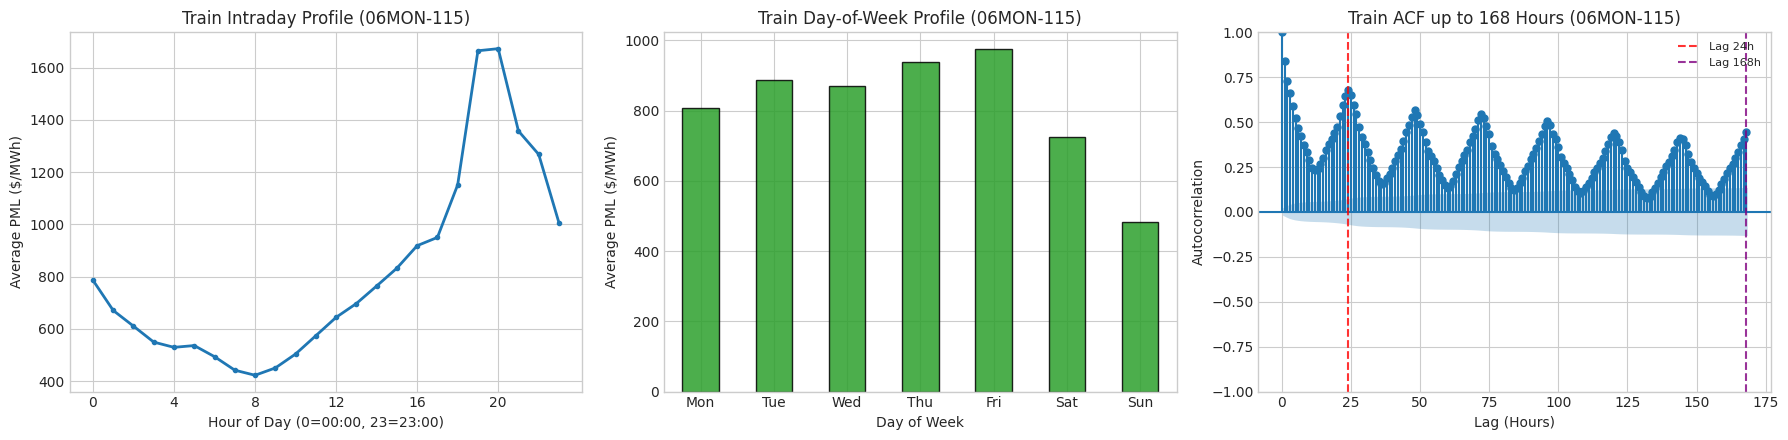

Lowest hourly mean:  Hour 8 ($422.33/MWh)
Highest hourly mean: Hour 20 ($1672.22/MWh)
Autocorrelation:     Lag 24h = 0.6808 | Lag 168h = 0.4437


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# A. Intraday hourly profile (00:00 to 23:00)
hourly_mean = df_ref.groupby('hour')['pml'].mean()
axes[0].plot(hourly_mean.index, hourly_mean.values, marker='o', markersize=3, color='#1f77b4', linewidth=2)
axes[0].set_title(f"Train Intraday Profile ({node_ref})")
axes[0].set_xlabel("Hour of Day (0=00:00, 23=23:00)")
axes[0].set_ylabel("Average PML ($/MWh)")
axes[0].set_xticks(range(0, 24, 4))

# B. Day-of-week profile
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_mean = df_ref.groupby('day_of_week')['pml'].mean().reindex(dow_order)
dow_mean.plot(kind='bar', ax=axes[1], color='#2ca02c', edgecolor='black', alpha=0.85)
axes[1].set_title(f"Train Day-of-Week Profile ({node_ref})")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Average PML ($/MWh)")
axes[1].set_xticklabels([d[:3] for d in dow_order], rotation=0)

# C. Autocorrelation Function (ACF) up to 168 hours
plot_acf(df_ref['pml'], lags=168, ax=axes[2], title=f"Train ACF up to 168 Hours ({node_ref})")
axes[2].set_xlabel("Lag (Hours)")
axes[2].set_ylabel("Autocorrelation")
axes[2].axvline(24, color='red', linestyle='--', alpha=0.8, label='Lag 24h')
axes[2].axvline(168, color='purple', linestyle='--', alpha=0.8, label='Lag 168h')
axes[2].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

print(f"Lowest hourly mean:  Hour {hourly_mean.idxmin()} (${hourly_mean.min():.2f}/MWh)")
print(f"Highest hourly mean: Hour {hourly_mean.idxmax()} (${hourly_mean.max():.2f}/MWh)")
print(f"Autocorrelation:     Lag 24h = {df_ref['pml'].autocorr(24):.4f} | Lag 168h = {df_ref['pml'].autocorr(168):.4f}")


### Finding 1 & Modeling Implication

- **Evidence (2024 Train):** Prices vary by hour of day and day of the week. Positive autocorrelation at lags 24h ($r = 0.6808$) and 168h ($r = 0.4437$), together with recurring ACF peaks at multiples of 24 hours, supports daily seasonality and a weekly dependency.

- **Decision:** Evaluate daily ($t-24$) and weekly ($t-168$) persistence baselines. Test **SARIMA** with a daily seasonal period ($s=24$) and **XGBoost** with historical price lags and calendar features. Select models based on temporal validation performance.

## Price Distribution & Scale (Metrics and Non-Linearities)
Evaluated strictly on training data (`df_ref`, year 2024).

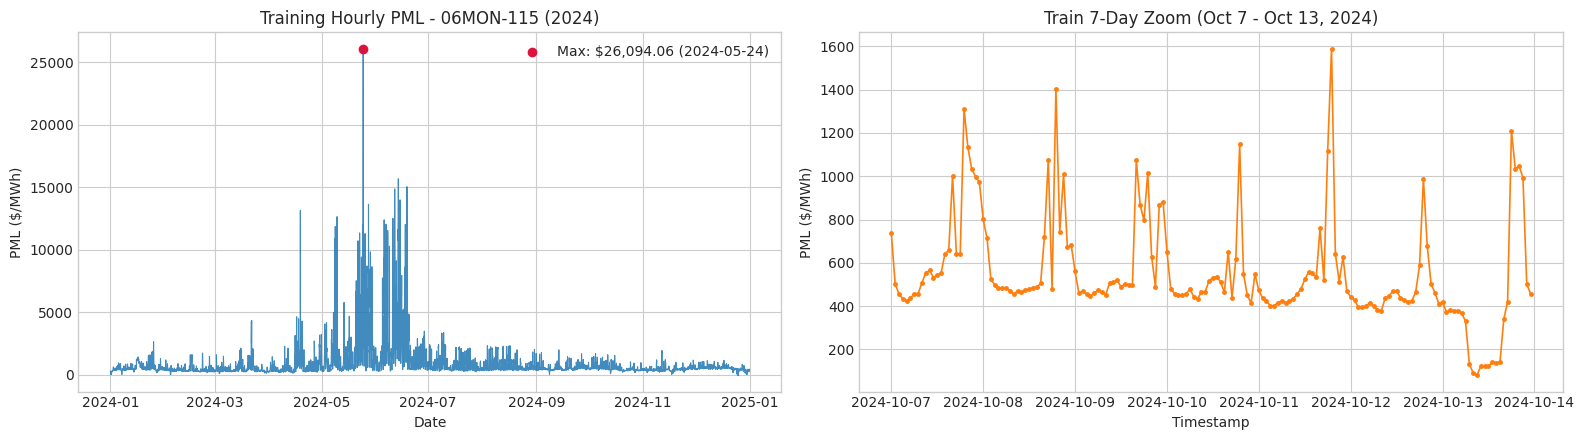

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

# Historical series for 2024
max_row = df_ref.loc[df_ref['pml'].idxmax()]
axes[0].plot(df_ref['timestamp'], df_ref['pml'], color='#1f77b4', linewidth=0.8, alpha=0.85)
axes[0].scatter(max_row['timestamp'], max_row['pml'], color='crimson', zorder=5, label=f"Max: ${max_row['pml']:,.2f} ({max_row['fecha']})")
axes[0].set_title(f"Training Hourly PML - {node_ref} (2024)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("PML ($/MWh)")
axes[0].legend(loc="upper right")

# 7-day zoomed window in training set (Oct 7 - Oct 13, 2024)
zoom_start, zoom_end = pd.to_datetime('2024-10-07 00:00:00'), pd.to_datetime('2024-10-13 23:00:00')
df_zoom = df_ref[(df_ref['timestamp'] >= zoom_start) & (df_ref['timestamp'] <= zoom_end)]
axes[1].plot(df_zoom['timestamp'], df_zoom['pml'], marker='o', markersize=2.5, color='#ff7f0e', linewidth=1.2)
axes[1].set_title(f"Train 7-Day Zoom (Oct 7 - Oct 13, 2024)")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("PML ($/MWh)")

plt.tight_layout()
plt.show()


### Finding 2 & Evaluation Implication

- **Evidence (2024 Train):** The historical series contains large price spikes and periods with zero or negative prices.

- **Proposed Evaluation:** Use **MAE** to measure average absolute forecast error in MXN/MWh, complemented by **RMSE** to emphasize large errors. Compare both metrics against daily and weekly persistence baselines. Avoid **MAPE** because the training data contains zero prices.

- **Model Comparison:** Compare **SARIMA** and **XGBoost** against the daily and weekly baselines using the same validation period. Price spikes alone do not establish which model will perform better.

## Correlation between all 9 Monclova Nodes

In [45]:
pml_train_wide = train_data.pivot(index='timestamp', columns='clv_nodo', values='pml')
corr_train = pml_train_wide.corr(method='pearson')
diffs_train = pml_train_wide.sub(pml_train_wide[node_ref], axis=0).abs()

summary_train_nodes = pd.DataFrame({
    'Correlation_vs_Ref': corr_train[node_ref],
    'Mean_Abs_Diff': diffs_train.mean(),
    'Median_Abs_Diff': diffs_train.median(),
    'Max_Abs_Diff': diffs_train.max(),
})

print(f"Minimum cross-node correlation in training set: {corr_train.values.min():.5f}")
print(f"Discrepancy table relative to {node_ref} on Train ($/MWh):")
display(summary_train_nodes)


Minimum cross-node correlation in training set: 1.00000
Discrepancy table relative to 06MON-115 on Train ($/MWh):


,Correlation_vs_Ref,Mean_Abs_Diff,Median_Abs_Diff,Max_Abs_Diff
clv_nodo,,,,
06AEO-115,1.000000,3.514587,1.580,128.21
06AHM-400,1.000000,1.701507,0.870,53.55
06FRO-115,1.000000,1.101441,0.610,38.01
06GRA-115,0.999999,3.041991,1.380,108.32
06MON-115,1.000000,0.000000,0.000,0.00
06MON-230,1.000000,0.139105,0.040,4.72
06RGS-115,1.000000,1.187253,0.445,39.48
06TKS-115,1.000000,0.948941,0.530,35.51
06XOC-115,0.999999,2.718958,1.270,91.55


### Finding 3 & Modeling Implication

- **Evidence (2024 Train):** All eight other nodes have a Pearson correlation above 0.9999 with `06MON-115`, with mean absolute price differences below 3.52 MXN/MWh.

- **Proposed Approach:** Evaluate a shared **XGBoost** model to learn common price dynamics across the nine nodes. Include the node identifier and price lags calculated separately for each node, and assess forecasting performance using per-node validation metrics.

## Forecasting Horizon

### Preventing Look-Ahead Bias in Day-Ahead Forecasting
- **Forecasting Horizon**: Predict all 24 hours of tomorrow ($D+1$, operating hours 1 to 24).
- **Information Availability**: When formulating forecasts for day $D+1$ on day $D$, prices for today (day $D$) are already published and known. Tomorrow's prices ($D+1$) are unobserved.
- **Feature Rules**: Using tomorrow's price at 14:00 to predict tomorrow at 15:00 (`lag_1` of the target day) is forbidden future leakage. Permitted historical lags are **Lag 24h** (same hour of today, $D$), **Lag 48h** (day $D-1$), and **Lag 168h** (day $D-6$, same hour of previous week), plus calendar variables.
